# Logistic Regression Classifier in Python - Basic Introduction



In logistic regression... basically, you are performing linear regression but applying a sigmoid function for the outcome.

#### Sigmoid  / Logistic Function

$p =1 / 1 + e^{-y}$

#### Properties of Logistic Regression
* Estimation is maximum likelihood estimation (MLE)

#### Advantages
* Straight forward, easy to implement, doesn't require high compute power, easy to interpret, used widely.
* Provides a probability score for observations.

#### Disadvantages
* Not able to handle a large number of category features/variables.
* Vulnerable to overfitting.


#### Data
Is the candy chocolate?  Let's find out...

In [1]:
# Import libraries, features and settings (not all of these are needed so pull what you need)

import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import io
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn import preprocessing
plt.rc("font", size = 14)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
sns.set(style="white")
sns.set(style="whitegrid", color_codes = True)

In [2]:
# Explore data

df = pd.read_csv('candy-data.csv')
df = df[['fruity','caramel','peanutyalmondy','nougat','crispedricewafer','hard', 'bar','pluribus','sugarpercent','pricepercent','winpercent','chocolate']]

df.head()

,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent,chocolate
0,0,1,0,0,1,0,1,0,0.732,0.860,66.971725,1
1,0,0,0,1,0,0,1,0,0.604,0.511,67.602936,1
2,0,0,0,0,0,0,0,0,0.011,0.116,32.261086,0
3,0,0,0,0,0,0,0,0,0.011,0.511,46.116505,0
4,1,0,0,0,0,0,0,0,0.906,0.511,52.341465,0


In [3]:
# Split data into train test sets
from sklearn.model_selection import train_test_split
trainingSet, testSet = train_test_split(df, test_size=0.2, random_state=42)

In [4]:
# Creating the dataframes for training and test datasets
train_df = trainingSet
test_df = testSet

#Clean the missing values if needed
#train_df = train_df.dropna()
#test_df = test_df.dropna()


In [5]:
#Since the data is already split into Train and Test datasets, load the values into X_train, X_test, y_train, y_test
#X_train = train_df.iloc[:,:-1].values
#y_train = train_df.iloc[:,1].values
#X_test = test_df.iloc[:,:-1].values
#y_test = test_df.iloc[:,1].values

X_train = train_df[['fruity','caramel','peanutyalmondy','nougat','crispedricewafer','hard', 'bar','pluribus','sugarpercent','pricepercent','winpercent']]

y_train = train_df["chocolate"]

X_test = test_df[['fruity','caramel','peanutyalmondy','nougat','crispedricewafer','hard', 'bar','pluribus','sugarpercent','pricepercent','winpercent']]

y_test = test_df["chocolate"]



In [6]:

y_test.head()

78    0
0     1
68    0
22    1
12    0
Name: chocolate, dtype: int64

### Data Exploration

In [7]:
y_train.value_counts()

chocolate
0    39
1    29
Name: count, dtype: int64

/tmp/ipykernel_2213/4146426988.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="chocolate", data=train_df, palette='Blues_d')


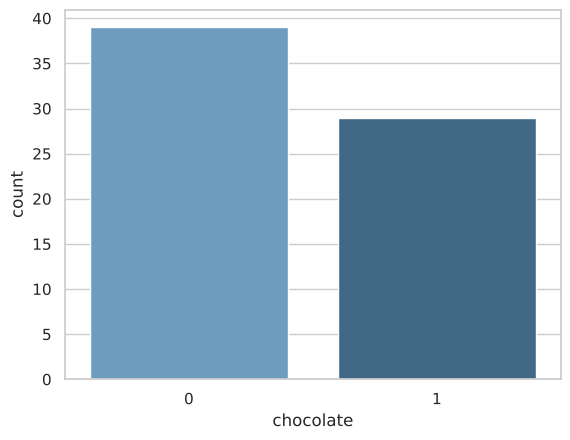

In [8]:
sns.countplot(x="chocolate", data=train_df, palette='Blues_d')
plt.savefig('count_plot')
plt.show()

In [9]:
count_no_choc = len(train_df[train_df['chocolate']==0])
count_choc = len(train_df[train_df['chocolate']==1])
pct_of_no_choc = count_no_choc/(count_no_choc+count_choc)
print("percentage of no chocolate is", pct_of_no_choc*100)
pct_of_choc = count_choc/(count_no_choc+count_choc)
print("percentage of chocolate", pct_of_choc*100)


percentage of no chocolate is 57.35294117647059
percentage of chocolate 42.64705882352941


In [10]:
train_df.groupby('chocolate').mean()

,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
chocolate,,,,,,,,,,,
0,0.717949,0.102564,0.051282,0.025641,0.000000,0.333333,0.025641,0.666667,0.476513,0.337923,41.225568
1,0.034483,0.275862,0.310345,0.172414,0.206897,0.034483,0.586207,0.275862,0.498621,0.639448,61.180606


In [11]:
train_df.groupby('caramel').mean()

,fruity,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent,chocolate
caramel,,,,,,,,,,,
0,0.500000,0.142857,0.035714,0.071429,0.232143,0.196429,0.571429,0.453750,0.433071,48.235961,0.375000
1,0.083333,0.250000,0.333333,0.166667,0.083333,0.583333,0.166667,0.636167,0.622583,56.735076,0.666667


### Model Development and Prediction
Import the Scikit Learn Logistic Regression module
Fit model on the train set using fit() then perform prediction on test set using prediction

In [12]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train,y_train)
y_pred = logreg.predict(X_test)

### Evaluate model using confusion matrix
This is basically looking at how well your model did on predictions

In [13]:
from sklearn import metrics
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[8, 1],
       [1, 7]])

### Visualize CFM (confusion matrix) using a heatmap

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

Text(0.5, 427.9555555555555, 'Predicted label')

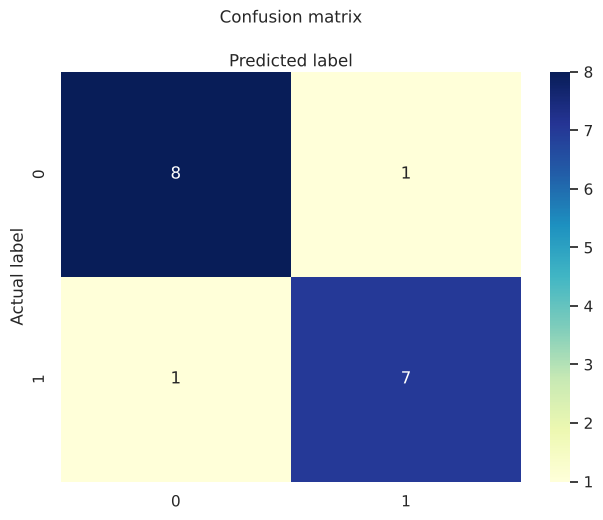

In [15]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

### CFM evaluation metrics Accuracy, Precision, Recall

In [16]:
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))
print("Precision:",metrics.precision_score(y_test, y_pred))
print("Recall:",metrics.recall_score(y_test, y_pred))

Accuracy: 0.8823529411764706
Precision: 0.875
Recall: 0.875


### ROC (Receiver Operation Characteristic) Curve
Plotting true positive rate against false positie rate. Shows tradeoff between sensitivity and specificity.

#### AUC - ROC curve
Is a performance measurement for classification problem at various thresholds settings. ROC is a probability curve and AUC represents degree or measure of separability. It tells how much model is capable of distinguishing between classes. Higher the AUC, better the model is at predicting 0s as 0s and 1s as 1s. By analogy, Higher the AUC, better the model is at distinguishing between patients with disease and no disease.

* The ROC curve is plotted with TPR against the FPR where TPR is on y-axis and FPR is on the x-axis.

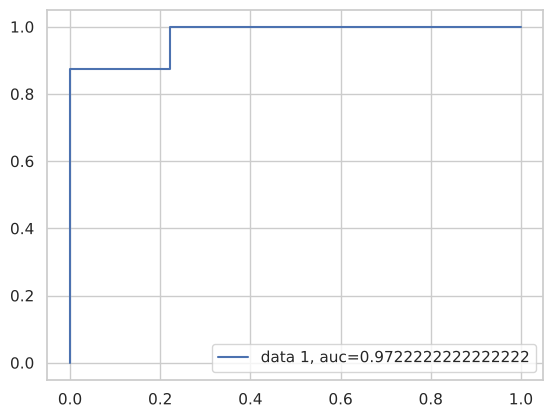

In [17]:
y_pred_proba = logreg.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()

### Activity

- What can you conclude about these results? 
- Compute all other classification metrics (recall, precision, F-measure, sensitivity, specificity, ... ) what can you say?
- Change the train_test_split percentage and give the results. 
- Use Cross-validation instead and report the results.
- Plot another AUC-ROC Curve using seaborn

In [18]:
# 1) Autres métriques de classification
from sklearn.metrics import classification_report, f1_score

tn, fp, fn, tp = metrics.confusion_matrix(y_test, y_pred).ravel()
print("TN =", tn, " FP =", fp, " FN =", fn, " TP =", tp)
print()
print("Accuracy                :", round(metrics.accuracy_score(y_test, y_pred), 4))
print("Precision               :", round(metrics.precision_score(y_test, y_pred), 4))
print("Recall / Sensibilité    :", round(metrics.recall_score(y_test, y_pred), 4))
print("Spécificité             :", round(tn / (tn + fp), 4))
print("F-measure (F1)          :", round(f1_score(y_test, y_pred), 4))
print("AUC                     :", round(auc, 4))
print()
print(classification_report(y_test, y_pred))

TN = 8  FP = 1  FN = 1  TP = 7

Accuracy                : 0.8824
Precision               : 0.875
Recall / Sensibilité    : 0.875
Spécificité             : 0.8889
F-measure (F1)          : 0.875
AUC                     : 0.9722

              precision    recall  f1-score   support

           0       0.89      0.89      0.89         9
           1       0.88      0.88      0.88         8

    accuracy                           0.88        17
   macro avg       0.88      0.88      0.88        17
weighted avg       0.88      0.88      0.88        17



**Conclusions :**

- Sur le jeu de test (17 bonbons) on obtient 15 bonnes prédictions sur 17 : accuracy = 0.88, precision = 0.875, recall = 0.875 et F1 = 0.875. Il y a 1 faux positif et 1 faux négatif seulement.
- La spécificité (0.889) et la sensibilité (0.875) sont proches, donc le modèle se trompe de la même façon sur les deux classes ; il n'y a pas de classe privilégiée (les classes sont assez équilibrées : 57% sans chocolat et 43% avec).
- L'AUC vaut 0.97, donc le modèle sépare très bien les bonbons au chocolat des autres.
- Attention : le jeu de test est très petit (17 observations), donc une seule erreur change l'accuracy de plus de 5 points. Ces résultats sont à prendre avec prudence.

In [19]:
# 2) Différents pourcentages de test
res = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    tr, te = train_test_split(df, test_size=t, random_state=42)
    Xa, ya = tr.drop('chocolate', axis=1), tr['chocolate']
    Xb, yb = te.drop('chocolate', axis=1), te['chocolate']
    m = LogisticRegression(max_iter=1000).fit(Xa, ya)
    p = m.predict(Xb)
    res.append((t, len(te), metrics.accuracy_score(yb, p), metrics.precision_score(yb, p),
                metrics.recall_score(yb, p), f1_score(yb, p), metrics.roc_auc_score(yb, m.predict_proba(Xb)[:, 1])))
print(pd.DataFrame(res, columns=['test_size', 'n_test', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC']).round(3).to_string(index=False))

 test_size  n_test  Accuracy  Precision  Recall    F1   AUC
       0.1       9     0.778      0.667   0.667 0.667 0.944
       0.2      17     0.882      0.875   0.875 0.875 0.972
       0.3      26     0.923      0.923   0.923 0.923 0.982
       0.4      34     0.941      0.938   0.938 0.938 0.972
       0.5      43     0.953      0.947   0.947 0.947 0.991


Quand on augmente la taille du jeu de test (donc qu'on diminue celle de l'entraînement) les métriques ne baissent pas : l'accuracy passe de 0.78 pour 10% à 0.95 pour 50%. Avec 10% de test il n'y a que 9 bonbons, donc le résultat est très instable (une ou deux erreurs suffisent pour faire baisser l'accuracy). Avec un jeu de test plus grand l'estimation est plus fiable. Le jeu de données ne contient que 85 observations, donc les résultats dépendent beaucoup du découpage et il vaut mieux utiliser la validation croisée.

In [20]:
# 3) Validation croisée (5 plis stratifiés)
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_all = df.drop('chocolate', axis=1)
y_all = df['chocolate']
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modele = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = cross_validate(modele, X_all, y_all, cv=skf, scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
for m_ in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    s = cv['test_' + m_]
    print(m_.ljust(10), "->", s.round(3), " moyenne =", round(s.mean(), 3), " écart-type =", round(s.std(), 3))

accuracy   -> [0.765 1.    0.824 0.941 0.882]  moyenne = 0.882  écart-type = 0.083
precision  -> [0.667 1.    1.    1.    1.   ]  moyenne = 0.933  écart-type = 0.133
recall     -> [1.    1.    0.571 0.857 0.714]  moyenne = 0.829  écart-type = 0.167
f1         -> [0.8   1.    0.727 0.923 0.833]  moyenne = 0.857  écart-type = 0.095
roc_auc    -> [0.931 1.    0.914 1.    0.943]  moyenne = 0.958  écart-type = 0.036


La validation croisée à 5 plis donne en moyenne : accuracy = 0.88, precision = 0.93, recall = 0.83, F1 = 0.86 et AUC = 0.96. Les scores varient d'un pli à l'autre (accuracy de 0.76 à 1.00), ce qui confirme que le résultat du simple train/test (0.88) était un peu dû au hasard du découpage. La precision est plus élevée que le recall : le modèle prédit "chocolat" avec prudence (peu de faux positifs) mais en rate quelques-uns. Ces valeurs de la validation croisée sont plus fiables que celles d'un seul découpage.

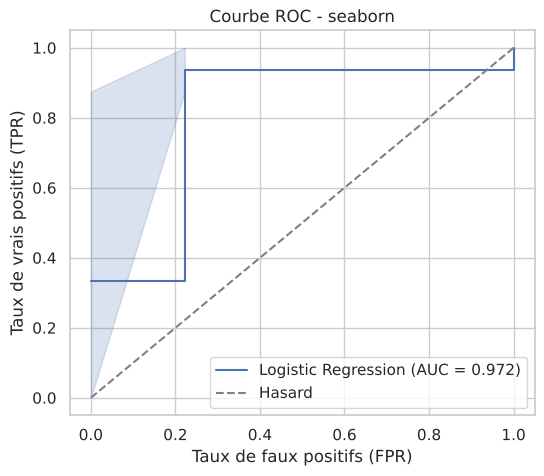

In [21]:
# 4) Courbe ROC avec seaborn
sns.set(style="whitegrid")
roc_df = pd.DataFrame({'FPR': fpr, 'TPR': tpr})
plt.figure(figsize=(6, 5))
sns.lineplot(x='FPR', y='TPR', data=roc_df, drawstyle='steps-post', label='Logistic Regression (AUC = ' + str(round(auc, 3)) + ')')
sns.lineplot(x=[0, 1], y=[0, 1], linestyle='--', color='gray', label='Hasard')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.title('Courbe ROC - seaborn')
plt.show()